# 04 · Modelo de Regresión Logística: probabilidad de defunción por dengue

**Proyecto final · Análisis Estadístico Multivariado**

**Entrada:** `datos-procesados/dengue_limpio.csv` (generado en `02_limpieza.ipynb` y explorado en `03_EDA.ipynb`).

**Objetivo:** estimar la probabilidad de que un paciente con dengue confirmado fallezca,

$$p = P(\text{DEFUNCION} = 1 \mid X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$$

e interpretar el efecto de cada variable mediante su *odds ratio* $e^{\beta_j}$.

**Decisiones que vienen del EDA**

| Hallazgo del EDA | Decisión en este notebook |
|---|---|
| Solo 0.70 % de fallecidos | *Undersampling* a 75 % sobrevivientes / 25 % fallecidos; partición estratificada; se evalúa con recall, precision, F1 y ROC-AUC además de accuracy |
| La edad no es lineal en el log-odds (forma de "U") | Se agrega el término `EDAD_ANOS_2` (edad²) y se revisa gráficamente |
| `HOSPITALIZADO` refleja la gravedad del paciente | Se compara el modelo final con y sin esta variable |
| Muchas variables con asociación débil | Selección de variables con *backward selection* (p-value, AIC y BIC) |

**Contenido**

1. Preparación de los datos (forma de la edad en el log-odds y *undersampling*)
2. División en entrenamiento y prueba
3. Modelo completo
4. Selección de variables (*backward selection*)
5. Modelo final: interpretación de coeficientes y *odds ratios*
6. Análisis de la variable `HOSPITALIZADO`
7. Separabilidad de las probabilidades estimadas
8. Métricas de desempeño (incluye la evaluación con la proporción real de fallecidos)
9. Conclusiones

## 1. Preparación de los datos

In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

# Cargar datos
dengue = pd.read_csv('datos-procesados/dengue_limpio.csv')
print('Dimensiones:', dengue.shape)
print(f"Tasa de mortalidad: {dengue['DEFUNCION'].mean() * 100:.2f} %")

Dimensiones: (251900, 29)
Tasa de mortalidad: 0.70 %


En el EDA se observó que la mortalidad tiene forma de "U" con respecto a la edad. Para que el modelo pueda capturar esa curvatura se agrega la variable **edad al cuadrado**. Con los dos términos, el log-odds de la edad es una parábola: $\beta_1 \cdot edad + \beta_2 \cdot edad^2$.

In [2]:
# Término cuadrático de la edad
dengue['EDAD_ANOS_2'] = dengue['EDAD_ANOS'] ** 2

# Variables independientes (X) y dependiente (y)
X = dengue.drop(columns=['ID_REGISTRO', 'DEFUNCION'])
y = dengue['DEFUNCION']
print('Variables independientes:', X.shape[1])
print(list(X.columns))

Variables independientes: 28
['HOMBRE', 'EDAD_ANOS', 'COSTERA', 'INDIGENA', 'HEMORRAGICOS', 'DIABETES', 'HIPERTENSION', 'ENFERMEDAD_RENAL', 'INMUNOSUPR', 'CIRROSIS_HEPATICA', 'EMBARAZO', 'HOSPITALIZADO', 'DENV2', 'DENV3', 'DENV4', 'SIN_SEROTIPO', 'MES_ENE', 'MES_FEB', 'MES_MAR', 'MES_ABR', 'MES_MAY', 'MES_JUN', 'MES_JUL', 'MES_AGO', 'MES_SEP', 'MES_NOV', 'MES_DIC', 'EDAD_ANOS_2']


### 1.1 ¿Cómo se ve $\beta_1 \cdot edad + \beta_2 \cdot edad^2$ frente a la mortalidad?

La regresión logística **no** supone que la probabilidad de fallecer cambie en línea recta con la edad. Lo que supone es que una transformación de la probabilidad, el **log-odds**, sí lo hace. Para revisar ese supuesto hay que calcular el log-odds directamente de los datos, sin usar el modelo, y ver qué forma tiene.

**De probabilidad a log-odds, paso a paso.** Se agrupan los pacientes en intervalos de 5 años de edad. En cada intervalo:

1. **Probabilidad (mortalidad):** fallecidos entre pacientes, $p = d / n$.
2. **Odds:** fallecidos entre sobrevivientes, $\dfrac{p}{1-p} = \dfrac{d}{n-d}$. Se lee como "por cada sobreviviente hay tantos fallecidos".
3. **Log-odds:** el logaritmo natural de los odds, $\ln\left(\dfrac{d}{n-d}\right)$. Es la escala en la que trabaja la regresión logística: $\ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \dots$

**Ejemplo con los menores de 5 años:** hay 6,828 pacientes y 80 fallecidos.

- Mortalidad: $80 / 6{,}828 = 1.17\,\%$.
- Odds: $80 / 6{,}748 = 0.0119$, es decir, aproximadamente 1 fallecido por cada 84 sobrevivientes.
- Log-odds: $\ln(0.0119) = -4.43$.

Como referencia para leer la gráfica: un log-odds de **−4.6 equivale a 1 %** de mortalidad, **−2.2 a 10 %** y **0 a 50 %**. Mientras más alto (menos negativo), mayor es el riesgo.

A este valor calculado con los datos se le llama **log-odds empírico**. En la práctica se le suma 0.5 a fallecidos y sobrevivientes, $\ln\left(\frac{d + 0.5}{n - d + 0.5}\right)$, para que no se indetermine si un intervalo no tiene muertes ($\ln 0$). Con miles de pacientes por intervalo, el cambio es mínimo.

Sobre esos puntos se dibujan dos modelos ajustados **solo con la edad** y con **todos** los datos (antes del *undersampling* y de la partición):

- **Solo lineal:** $\beta_0 + \beta_1 \cdot edad$, una recta en la escala del log-odds.
- **Cuadrático:** $\beta_0 + \beta_1 \cdot edad + \beta_2 \cdot edad^2$, una parábola en la escala del log-odds.

Si la edad fuera lineal en el log-odds, los puntos caerían sobre la recta.

Lineal:     log-odds = -5.9339 + 0.02912·edad   (AIC = 20,427.7)
Cuadrático: log-odds = -4.9291 + (-0.03615)·edad + 0.000757·edad²   (AIC = 20,139.9)
Vértice de la parábola (edad de menor riesgo): 23.9 años


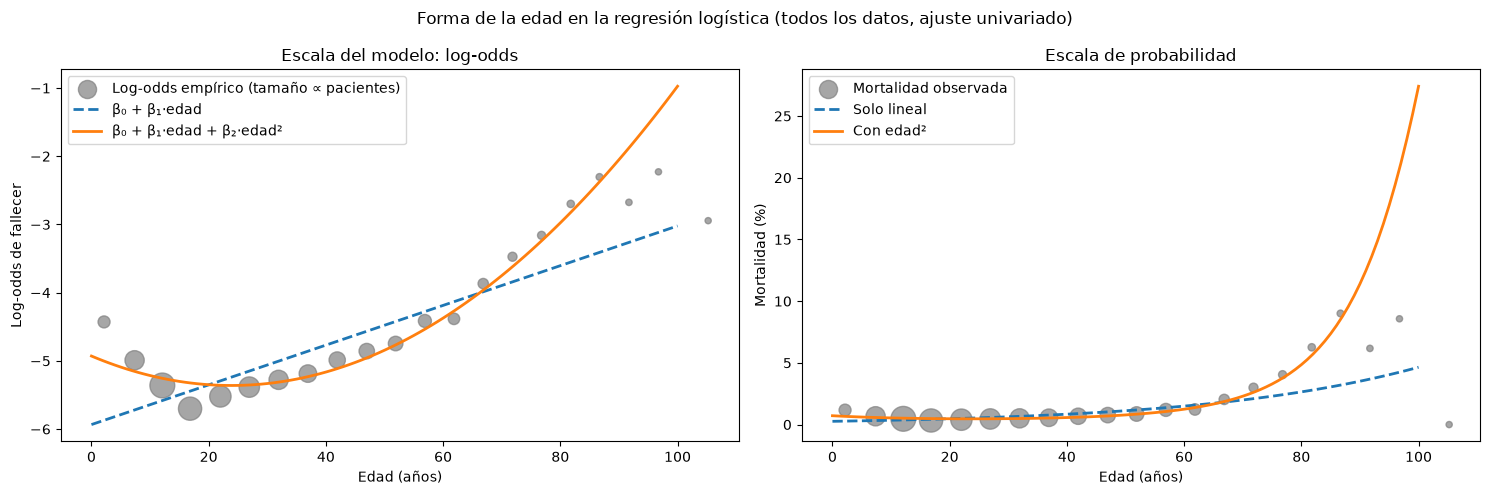

,Edad promedio,Pacientes (n),Fallecidos (d),Mortalidad (%),Odds (d / sobrevivientes),Log-odds empírico
EDAD_ANOS,,,,,,
0,2.1520,6828,80,1.1716,0.0119,-4.4288
5,7.3636,21399,144,0.6729,0.0068,-4.9911
10,12.0936,37311,174,0.4664,0.0047,-5.3605
15,16.8265,32252,107,0.3318,0.0033,-5.7005
20,21.9995,26974,107,0.3967,0.0040,-5.5212
25,26.9297,24421,111,0.4545,0.0046,-5.3846
30,31.9370,21373,108,0.5053,0.0051,-5.2781
35,36.9360,17353,96,0.5532,0.0056,-5.1865
40,41.9313,14681,99,0.6743,0.0068,-4.9874


In [3]:
# Log-odds empírico por intervalos de 5 años de edad
bins = np.arange(0, 105, 5)
grupo = pd.cut(dengue['EDAD_ANOS'], bins=np.append(bins, np.inf), right=False, labels=bins)
resumen_edad = dengue.groupby(grupo, observed=True)['DEFUNCION'].agg(n='size', d='sum')
resumen_edad['edad_media'] = dengue.groupby(grupo, observed=True)['EDAD_ANOS'].mean()
resumen_edad['logit_emp'] = np.log((resumen_edad['d'] + 0.5) / (resumen_edad['n'] - resumen_edad['d'] + 0.5))
resumen_edad['mortalidad'] = resumen_edad['d'] / resumen_edad['n']

# Ajustes univariados: solo edad y edad + edad²
logit_lineal = sm.Logit(dengue['DEFUNCION'], sm.add_constant(dengue[['EDAD_ANOS']])).fit(disp=0)
logit_cuad = sm.Logit(dengue['DEFUNCION'], sm.add_constant(dengue[['EDAD_ANOS', 'EDAD_ANOS_2']])).fit(disp=0)
b0, b1, b2 = logit_cuad.params
print(f'Lineal:     log-odds = {logit_lineal.params.iloc[0]:.4f} + {logit_lineal.params.iloc[1]:.5f}·edad   (AIC = {logit_lineal.aic:,.1f})')
print(f'Cuadrático: log-odds = {b0:.4f} + ({b1:.5f})·edad + {b2:.6f}·edad²   (AIC = {logit_cuad.aic:,.1f})')
print(f'Vértice de la parábola (edad de menor riesgo): {-b1 / (2 * b2):.1f} años')

edades_graf = np.arange(0, 101)
eta_lineal = logit_lineal.params.iloc[0] + logit_lineal.params.iloc[1] * edades_graf
eta_cuad = b0 + b1 * edades_graf + b2 * edades_graf ** 2
tamanos = 20 + 300 * resumen_edad['n'] / resumen_edad['n'].max()

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
ejes[0].scatter(resumen_edad['edad_media'], resumen_edad['logit_emp'], s=tamanos, color='gray', alpha=0.7,
                label='Log-odds empírico (tamaño ∝ pacientes)')
ejes[0].plot(edades_graf, eta_lineal, '--', lw=2, label='β₀ + β₁·edad')
ejes[0].plot(edades_graf, eta_cuad, lw=2, label='β₀ + β₁·edad + β₂·edad²')
ejes[0].set_xlabel('Edad (años)')
ejes[0].set_ylabel('Log-odds de fallecer')
ejes[0].set_title('Escala del modelo: log-odds')
ejes[0].legend()

ejes[1].scatter(resumen_edad['edad_media'], resumen_edad['mortalidad'] * 100, s=tamanos, color='gray', alpha=0.7,
                label='Mortalidad observada')
ejes[1].plot(edades_graf, 100 / (1 + np.exp(-eta_lineal)), '--', lw=2, label='Solo lineal')
ejes[1].plot(edades_graf, 100 / (1 + np.exp(-eta_cuad)), lw=2, label='Con edad²')
ejes[1].set_xlabel('Edad (años)')
ejes[1].set_ylabel('Mortalidad (%)')
ejes[1].set_title('Escala de probabilidad')
ejes[1].legend()
plt.suptitle('Forma de la edad en la regresión logística (todos los datos, ajuste univariado)')
plt.tight_layout()
plt.show()

pd.DataFrame({
    'Edad promedio': resumen_edad['edad_media'],
    'Pacientes (n)': resumen_edad['n'],
    'Fallecidos (d)': resumen_edad['d'],
    'Mortalidad (%)': resumen_edad['mortalidad'] * 100,
    'Odds (d / sobrevivientes)': resumen_edad['d'] / (resumen_edad['n'] - resumen_edad['d']),
    'Log-odds empírico': resumen_edad['logit_emp'],
}).round(4)

**Interpretación.**

- **La edad no es lineal en el log-odds.** En la gráfica izquierda, los puntos grises no siguen la recta punteada. Bajan de los 0 a los ~15–20 años (de −4.4 a −5.7) y después suben cada vez más rápido (−4.4 a los 60 años y −2.3 a los 85). La recta subestima el riesgo de los niños y de los adultos mayores y lo sobreestima entre los 20 y los 50 años.
- **La parábola se ajusta mucho mejor.** El coeficiente lineal es negativo ($\beta_1 = -0.036$) y el cuadrático positivo ($\beta_2 = 0.00076$), lo que forma una "U" con mínimo cerca de los **24 años**. El AIC baja ≈ 290 unidades respecto a la recta.
- **En la escala de probabilidad** (gráfica derecha), la mortalidad es casi plana (≈ 0.5 %) hasta los 60 años y después crece rápido: 2 % a los 65–69, 4 % a los 75–79 y 9 % a los 85–89.
- **El ajuste no es perfecto en los extremos.** En menores de 5 años la mortalidad observada (1.2 %) queda por encima de la parábola. Después de los 90 años la parábola sigue subiendo mientras los datos se estabilizan, pero con muy pocos pacientes (puntos pequeños), así que pesan poco en el ajuste.
- El modelo sigue siendo **lineal en los parámetros** ($\beta$); lo que cambia es que la edad entra con dos términos para representar la "U".

### 1.2 *Undersampling*: 75 % sobrevivientes / 25 % fallecidos

Solo el 0.70 % de los pacientes fallece. Para que el modelo vea más fallecidos en proporción, se hace un **submuestreo aleatorio de la clase mayoritaria**: se conservan **todos** los fallecidos y se toma al azar un número de sobrevivientes igual a 3 veces el número de fallecidos, de modo que la muestra queda con **75 % sobrevivientes y 25 % fallecidos**. Las secciones siguientes (partición, ajuste y evaluación) usan esta muestra.

**Consecuencias que hay que tener presentes:**

- **Se descarta información:** de 250,137 sobrevivientes solo se usan 5,289 (2 %).
- **El intercepto cambia:** el modelo estima probabilidades en una población con 25 % de mortalidad, no 0.70 %. Los *odds ratios* de las variables **no se ven afectados** por un muestreo que depende solo del desenlace, pero las probabilidades absolutas sí quedan infladas. Para regresarlas a la escala real se corrige el intercepto con $\beta_0^{real} = \beta_0 - \ln\left(\frac{0.25 / 0.75}{\pi / (1 - \pi)}\right)$, donde $\pi$ es la tasa real de mortalidad.
- **El conjunto de prueba también queda balanceado** porque se divide después del *undersampling*. Métricas como precision, F1 y accuracy se calculan con 25 % de fallecidos, no con la proporción real; el ROC-AUC y el recall no dependen de la proporción de clases.

In [4]:
fallecidos = dengue[dengue['DEFUNCION'] == 1]
sobrevivientes = dengue[dengue['DEFUNCION'] == 0].sample(n=3 * len(fallecidos), random_state=42)
dengue_us = pd.concat([fallecidos, sobrevivientes]).sample(frac=1, random_state=42)  # mezclar filas

pd.DataFrame({
    'Casos': [len(dengue), len(dengue_us)],
    'Fallecidos': [dengue['DEFUNCION'].sum(), dengue_us['DEFUNCION'].sum()],
    'Sobrevivientes': [(dengue['DEFUNCION'] == 0).sum(), (dengue_us['DEFUNCION'] == 0).sum()],
    'Mortalidad (%)': [dengue['DEFUNCION'].mean() * 100, dengue_us['DEFUNCION'].mean() * 100],
}, index=['Original', 'Undersampling 75/25']).round(2)

,Casos,Fallecidos,Sobrevivientes,Mortalidad (%)
Original,251900,1763,250137,0.7
Undersampling 75/25,7052,1763,5289,25.0


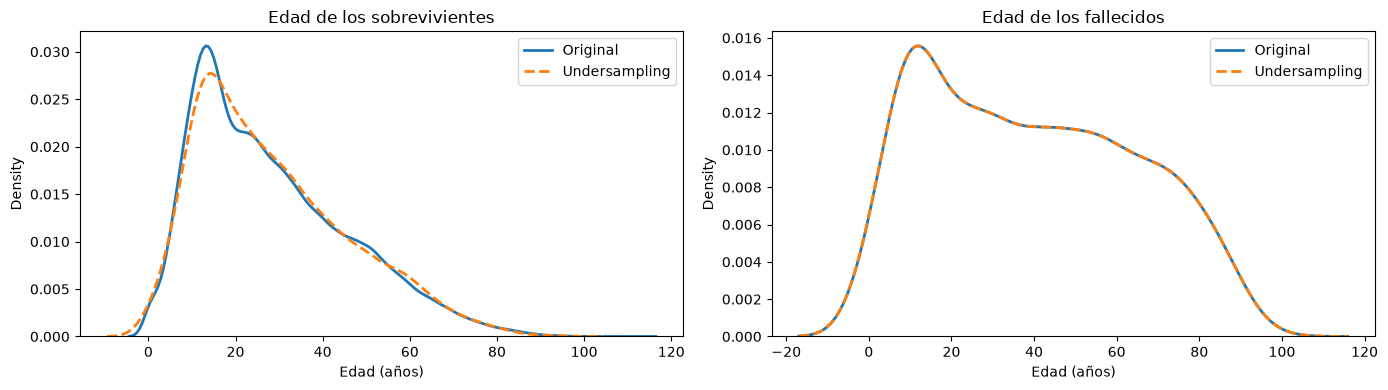

Dimensiones de X: (7052, 28)


In [5]:
# La edad conserva su distribución dentro de cada clase (el muestreo solo depende del desenlace)
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for eje, clase, nombre in [(ejes[0], 0, 'Sobrevivientes'), (ejes[1], 1, 'Fallecidos')]:
    sns.kdeplot(dengue.loc[dengue['DEFUNCION'] == clase, 'EDAD_ANOS'], ax=eje, lw=2, label='Original')
    sns.kdeplot(dengue_us.loc[dengue_us['DEFUNCION'] == clase, 'EDAD_ANOS'], ax=eje, lw=2, ls='--', label='Undersampling')
    eje.set_title(f'Edad de los {nombre.lower()}')
    eje.set_xlabel('Edad (años)')
    eje.legend()
plt.tight_layout()
plt.show()

# Variables independientes (X) y dependiente (y) a partir de la muestra balanceada
X = dengue_us.drop(columns=['ID_REGISTRO', 'DEFUNCION'])
y = dengue_us['DEFUNCION']
print('Dimensiones de X:', X.shape)

**Interpretación.** La muestra balanceada tiene **7,052 pacientes**: los 1,763 fallecidos y 5,289 sobrevivientes. La distribución de la edad de los sobrevivientes muestreados es prácticamente igual a la original, así que el submuestreo aleatorio no introdujo un sesgo de edad dentro de cada clase.

## 2. División en entrenamiento y prueba

Si el modelo se evaluara con los mismos datos con los que se ajustó, las métricas serían optimistas: el modelo podría estar memorizando los datos (*overfitting*) en lugar de aprender patrones generales. Por eso se separa un **conjunto de prueba** que el modelo nunca ve durante el ajuste ni durante la selección de variables, y que solo se usa al final para medir su desempeño en datos nuevos.

- **70 % entrenamiento / 30 % prueba.**
- **Estratificado por `DEFUNCION`** (`stratify=y`): ambos conjuntos conservan la proporción 75 / 25 de la muestra balanceada.
- `random_state=42` para que el resultado sea reproducible.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

pd.DataFrame({
    'Casos': [len(y_train), len(y_test)],
    'Fallecidos': [y_train.sum(), y_test.sum()],
    'Mortalidad (%)': [y_train.mean() * 100, y_test.mean() * 100],
}, index=['Entrenamiento', 'Prueba']).round(3)

,Casos,Fallecidos,Mortalidad (%)
Entrenamiento,4936,1234,25.0
Prueba,2116,529,25.0


Ambos conjuntos conservan la misma tasa de mortalidad (25 %), así que la estratificación funcionó.

## 3. Modelo completo

Se ajusta primero una regresión logística con **todas** las variables, usando `statsmodels` sobre el conjunto de entrenamiento.

In [7]:
modelo_completo = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)
print(modelo_completo.summary())

                           Logit Regression Results                           
Dep. Variable:              DEFUNCION   No. Observations:                 4936
Model:                          Logit   Df Residuals:                     4907
Method:                           MLE   Df Model:                           28
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.3264
Time:                        20:30:42   Log-Likelihood:                -1869.8
converged:                       True   LL-Null:                       -2775.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -4.2818      0.302    -14.163      0.000      -4.874      -3.689
HOMBRE                0.0566      0.083      0.683      0.495      -0.106       0.219
EDAD_ANOS            -0.

**Lectura de los estadísticos del modelo:**

- **Log-Likelihood (−1,869.8) vs. LL-Null (−2,775.7):** el modelo con predictores tiene una log-verosimilitud mucho mayor que el modelo sin predictores (que solo predice la tasa promedio de 25 %), es decir, las variables sí aportan información.
- **LLR p-value ≈ 0:** la prueba de razón de verosimilitudes rechaza que todos los coeficientes sean cero. El modelo en conjunto es significativo.
- **Pseudo R² = 0.326:** el modelo mejora en 32.6 % la log-verosimilitud del modelo nulo, un buen ajuste según el rango habitual (0.2 a 0.4). **No es comparable** con un modelo ajustado sobre los datos originales: el pseudo R² depende de la proporción de clases, y con 25 % de fallecidos el modelo nulo es mucho peor que con 0.70 %.
- **Coeficientes:** son significativos (p-value < 0.05) la edad y edad², hemorrágicos, diabetes, enfermedad renal, hospitalización, DENV4 e indígena. No lo son sexo, entidad costera, hipertensión, inmunosupresión, cirrosis, embarazo, los demás serotipos y todos los meses. Esto justifica simplificar el modelo con *backward selection*.

## 4. Selección de variables: *backward selection*

Procedimiento:

1. Ajustar el modelo con todas las variables.
2. Identificar la variable con el **p-value más alto**.
3. Si ese p-value es mayor que el nivel de significancia ($\alpha = 0.05$), eliminar la variable y volver a ajustar el modelo.
4. Repetir hasta que todas las variables sean significativas.

En cada paso se registran el **AIC** y el **BIC** (criterios de información: penalizan la complejidad del modelo; **menor es mejor**). El BIC penaliza más el número de variables que el AIC.

In [8]:
alpha = 0.05
variables = list(X_train.columns)
pasos = []

while True:
    modelo = sm.Logit(y_train, sm.add_constant(X_train[variables])).fit(disp=0)
    p_values = modelo.pvalues.drop('const')
    peor = p_values.idxmax()
    pasos.append({'Núm. variables': len(variables), 'AIC': modelo.aic, 'BIC': modelo.bic,
                  'Variable con mayor p-value': peor, 'p-value': p_values.max()})
    if p_values.max() <= alpha:     # todas son significativas: se detiene
        break
    variables.remove(peor)          # se elimina la menos significativa

pasos = pd.DataFrame(pasos)
pasos['Acción'] = np.where(pasos['p-value'] > alpha, 'Se elimina', 'Se detiene (todas significativas)')
pasos.round(3)

,Núm. variables,AIC,BIC,Variable con mayor p-value,p-value,Acción
0,28,3797.650,3986.275,MES_ENE,0.941,Se elimina
1,27,3795.655,3977.776,MES_MAR,0.840,Se elimina
2,26,3793.696,3969.312,MES_DIC,0.831,Se elimina
3,25,3791.742,3960.854,MES_AGO,0.635,Se elimina
4,24,3789.968,3952.576,MES_SEP,0.713,Se elimina
5,23,3788.103,3944.207,COSTERA,0.582,Se elimina
6,22,3786.405,3936.004,CIRROSIS_HEPATICA,0.567,Se elimina
7,21,3784.735,3927.830,HOMBRE,0.499,Se elimina
8,20,3783.191,3919.782,MES_ABR,0.371,Se elimina
9,19,3781.981,3912.068,MES_FEB,0.342,Se elimina


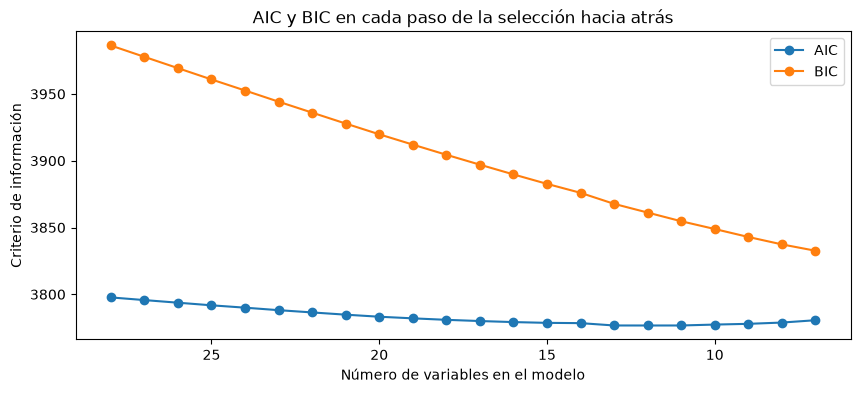

Variables finales: ['EDAD_ANOS', 'HEMORRAGICOS', 'DIABETES', 'ENFERMEDAD_RENAL', 'HOSPITALIZADO', 'DENV4', 'EDAD_ANOS_2']


In [9]:
plt.figure(figsize=(10, 4))
plt.plot(pasos['Núm. variables'], pasos['AIC'], marker='o', label='AIC')
plt.plot(pasos['Núm. variables'], pasos['BIC'], marker='o', label='BIC')
plt.gca().invert_xaxis()
plt.xlabel('Número de variables en el modelo')
plt.ylabel('Criterio de información')
plt.title('AIC y BIC en cada paso de la selección hacia atrás')
plt.legend()
plt.show()

print('Variables finales:', variables)

**Interpretación.**

- Se eliminaron **21 variables** en este orden: 5 dummies de mes (enero, marzo, diciembre, agosto, septiembre), entidad costera, cirrosis, sexo, 3 meses más (abril, febrero, noviembre), DENV2, embarazo, sin serotipo, DENV3, hipertensión, mayo, inmunosupresión, julio, junio e indígena. El modelo final tiene **7 variables**: edad, edad², hemorrágicos, diabetes, enfermedad renal, hospitalización y DENV4.
- El **BIC baja en todos los pasos** (de 3,986 a 3,833): según este criterio, el modelo de 7 variables es el mejor.
- El **AIC** baja poco y tiene su mínimo en 12 variables (3,776.6). El modelo final queda 3.9 unidades arriba, una diferencia pequeña pero mayor a 2. Es decir, el AIC preferiría conservar algunas variables más (inmunosupresión, julio, junio e indígena, todas con p-values entre 0.05 y 0.12), mientras que el BIC, que penaliza más la complejidad, prefiere el modelo más simple. Se elige el modelo de 7 variables porque todas son significativas y es el más sencillo de interpretar.
- **Comparación con el modelo sin *undersampling*:** cirrosis, inmunosupresión y los meses de abril y junio, que antes quedaban en el modelo, ahora se eliminan. No significa que dejen de importar: al descartar el 98 % de los sobrevivientes hay menos pacientes con estas condiciones (que ya eran raras), los errores estándar crecen y los p-values suben. Es una pérdida de **potencia estadística** propia del *undersampling*.
- **Nota sobre los meses:** como ningún mes quedó en el modelo, la estacionalidad no aporta información una vez que se consideran las demás variables.

In [10]:
# ¿Se justifica el término edad²? Modelo final con y sin él
sin_edad2 = [v for v in variables if v != 'EDAD_ANOS_2']
modelo_sin_edad2 = sm.Logit(y_train, sm.add_constant(X_train[sin_edad2])).fit(disp=0)

pd.DataFrame({
    'AIC': [modelo.aic, modelo_sin_edad2.aic],
    'BIC': [modelo.bic, modelo_sin_edad2.bic],
    'Pseudo R²': [modelo.prsquared, modelo_sin_edad2.prsquared],
}, index=['Con edad²', 'Sin edad²']).round(3)

,AIC,BIC,Pseudo R²
Con edad²,3780.571,3832.606,0.322
Sin edad²,3838.024,3883.554,0.311


**Interpretación.** Al quitar edad², el AIC sube 57 unidades y el BIC 51, y el pseudo R² baja de 0.322 a 0.311. El término cuadrático mejora claramente el modelo, lo que confirma lo observado en la gráfica de la sección 1.1: la relación entre la edad y el log-odds de fallecer **no es lineal**.

## 5. Modelo final: interpretación de coeficientes y *odds ratios*

In [11]:
modelo_final = sm.Logit(y_train, sm.add_constant(X_train[variables])).fit(disp=0)
print(modelo_final.summary())

                           Logit Regression Results                           
Dep. Variable:              DEFUNCION   No. Observations:                 4936
Model:                          Logit   Df Residuals:                     4928
Method:                           MLE   Df Model:                            7
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.3219
Time:                        20:30:42   Log-Likelihood:                -1882.3
converged:                       True   LL-Null:                       -2775.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -3.8135      0.180    -21.191      0.000      -4.166      -3.461
EDAD_ANOS           -0.0308      0.007     -4.372      0.000      -0.045      -0.017
HEMORRAGICOS         1.1270 

In [12]:
# Odds ratio = e^beta, con su intervalo de confianza al 95 %
ic = np.exp(modelo_final.conf_int())
odds_ratios = pd.DataFrame({
    'Coeficiente (β)': modelo_final.params,
    'Odds ratio (e^β)': np.exp(modelo_final.params),
    'IC 95% inferior': ic[0],
    'IC 95% superior': ic[1],
    'p-value': modelo_final.pvalues,
}).drop(index='const').sort_values('Odds ratio (e^β)', ascending=False)
odds_ratios.round(4)

,Coeficiente (β),Odds ratio (e^β),IC 95% inferior,IC 95% superior,p-value
HOSPITALIZADO,3.5164,33.6625,25.2392,44.8969,0.0000
DENV4,1.6155,5.0305,1.6149,15.6702,0.0053
ENFERMEDAD_RENAL,1.2355,3.4402,1.7118,6.9135,0.0005
HEMORRAGICOS,1.1270,3.0863,1.7273,5.5146,0.0001
DIABETES,0.6772,1.9684,1.3920,2.7834,0.0001
EDAD_ANOS_2,0.0007,1.0007,1.0005,1.0008,0.0000
EDAD_ANOS,-0.0308,0.9696,0.9563,0.9831,0.0000


**Interpretación de los *odds ratios*** (manteniendo constantes las demás variables):

| Variable | OR (IC 95 %) | Interpretación |
|---|---|---|
| Hospitalizado | 33.7 (25.2–44.9) | Los odds de fallecer de un paciente hospitalizado son **34 veces** los de un paciente ambulatorio |
| DENV4 | 5.0 (1.6–15.7) | Multiplica los odds por 5, pero con un intervalo muy amplio (ver nota) |
| Enfermedad renal | 3.4 (1.7–6.9) | Tener enfermedad renal multiplica los odds de fallecer por 3.4 |
| Hemorrágicos | 3.1 (1.7–5.5) | Multiplica los odds por 3.1 |
| Diabetes | 2.0 (1.4–2.8) | Multiplica los odds por 2 |

Ningún intervalo de confianza incluye al 1, es decir, todas las variables **aumentan** el riesgo de forma significativa.

**Los *odds ratios* siguen siendo válidos con *undersampling*.** Como la muestra se tomó solo en función del desenlace (se eligieron sobrevivientes al azar, sin ver sus características), el muestreo solo cambia el intercepto. Los OR son parecidos a los del modelo sin *undersampling* (hospitalización 31.4, enfermedad renal 4.2, diabetes 1.7); hemorrágicos sube de 1.9 a 3.1, dentro de la incertidumbre de una variable con pocos casos.

**Nota sobre DENV4:** el resultado se basa en muy pocos pacientes: solo 31 en el conjunto de entrenamiento (11 fallecidos). En los datos completos, la mortalidad con DENV4 es de 0.86 % (12 de 1,396 pacientes), muy parecida a la general (0.70 %), y en el modelo sin *undersampling* no era significativo. Es probable que sea un efecto de la muestra y no un riesgo real, por lo que **no debe tomarse como una conclusión firme**.

**Edad:** sus coeficientes no se interpretan por separado. El coeficiente lineal es negativo (−0.031) y el cuadrático positivo (0.0007), lo que forma la parábola de la sección 1.1: el riesgo baja en las primeras edades y después sube cada vez más rápido. Su efecto se muestra en la siguiente gráfica. Como el modelo se ajustó con 25 % de fallecidos, primero se corrige el intercepto para que las probabilidades correspondan a la mortalidad real (0.70 %).

Corrección del intercepto: β0 = -3.814 → -7.670

Ambulatorio: edad con menor riesgo = 23 años | prob. a los 0 años = 0.05 %, 20 años = 0.03 %, 60 años = 0.08 %, 85 años = 0.41 %
Hospitalizado: edad con menor riesgo = 23 años | prob. a los 0 años = 1.55 %, 20 años = 1.09 %, 60 años = 2.64 %, 85 años = 12.29 %


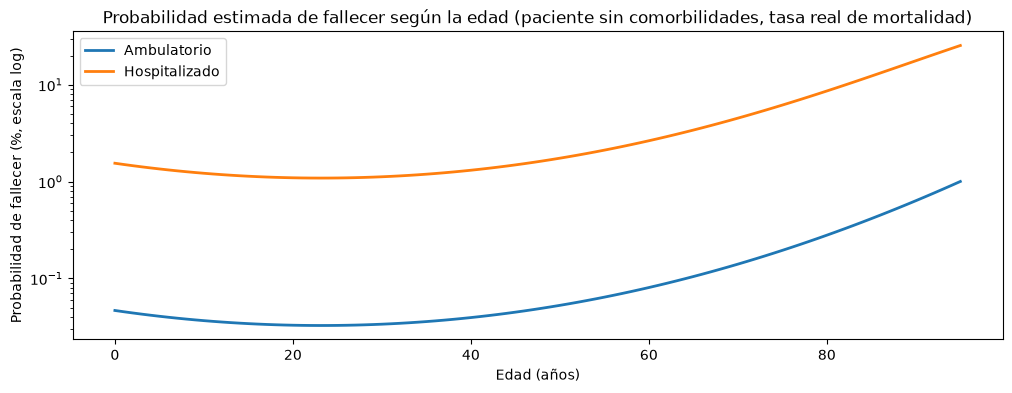

In [13]:
# Efecto de la edad: probabilidad estimada para un paciente de referencia
# (sin comorbilidades, sin hemorragia, serotipo distinto de DENV4), ambulatorio y hospitalizado.
# El modelo se ajustó con 25 % de fallecidos; se corrige el intercepto para regresar a la tasa real de mortalidad.
pi_real = dengue['DEFUNCION'].mean()
pi_muestra = y_train.mean()
correccion = np.log((pi_muestra / (1 - pi_muestra)) / (pi_real / (1 - pi_real)))
print(f'Corrección del intercepto: β0 = {modelo_final.params["const"]:.3f} → {modelo_final.params["const"] - correccion:.3f}\n')

edades = np.arange(0, 96)
plt.figure(figsize=(12, 4))
for hosp, etiqueta in [(0, 'Ambulatorio'), (1, 'Hospitalizado')]:
    perfil = pd.DataFrame(0, index=edades, columns=variables)
    perfil['EDAD_ANOS'] = edades
    perfil['EDAD_ANOS_2'] = edades ** 2
    perfil['HOSPITALIZADO'] = hosp
    log_odds = modelo_final.predict(sm.add_constant(perfil, has_constant='add'), which='linear') - correccion
    prob = 1 / (1 + np.exp(-log_odds.values))
    plt.plot(edades, prob * 100, lw=2, label=etiqueta)
    print(f'{etiqueta}: edad con menor riesgo = {edades[np.argmin(prob)]} años | '
          f'prob. a los 0 años = {prob[0]*100:.2f} %, 20 años = {prob[20]*100:.2f} %, '
          f'60 años = {prob[60]*100:.2f} %, 85 años = {prob[85]*100:.2f} %')
plt.yscale('log')
plt.xlabel('Edad (años)')
plt.ylabel('Probabilidad de fallecer (%, escala log)')
plt.title('Probabilidad estimada de fallecer según la edad (paciente sin comorbilidades, tasa real de mortalidad)')
plt.legend()
plt.show()

**Interpretación.** Al corregir el intercepto (de −3.81 a −7.67), las probabilidades regresan a la escala real. Para un paciente sin comorbilidades, el riesgo es mínimo alrededor de los **23 años** y aumenta en ambos extremos, como se vio en la sección 1.1. Para un paciente **hospitalizado**, la probabilidad de fallecer pasa de 1.1 % a los 20 años a 2.6 % a los 60 y a **12.3 % a los 85**; un recién nacido hospitalizado tiene 1.6 %. En pacientes **ambulatorios** el riesgo es mucho menor en todas las edades (0.03 % a los 20 años y 0.41 % a los 85).

Sin la corrección, el modelo daría probabilidades mucho más altas (por ejemplo, ≈ 87 % para un hospitalizado de 85 años), porque las calcula para una población donde 1 de cada 4 pacientes fallece.

## 6. Análisis de la variable `HOSPITALIZADO`

Uno de los supuestos de la regresión logística es que las variables independientes **no deben ser afectadas por la variable dependiente** (endogeneidad). La hospitalización no es causada por la muerte, pero sí es una **consecuencia de la gravedad** del paciente: los pacientes más graves se hospitalizan y también tienen mayor riesgo de morir. Por eso se compara el modelo final con el mismo modelo **sin** `HOSPITALIZADO`.

In [14]:
sin_hosp = [v for v in variables if v != 'HOSPITALIZADO']
modelo_sin_hosp = sm.Logit(y_train, sm.add_constant(X_train[sin_hosp])).fit(disp=0)

comparacion = pd.DataFrame({
    'AIC': [modelo_final.aic, modelo_sin_hosp.aic],
    'BIC': [modelo_final.bic, modelo_sin_hosp.bic],
    'Pseudo R²': [modelo_final.prsquared, modelo_sin_hosp.prsquared],
    'ROC-AUC (prueba)': [roc_auc_score(y_test, modelo_final.predict(sm.add_constant(X_test[variables]))),
                         roc_auc_score(y_test, modelo_sin_hosp.predict(sm.add_constant(X_test[sin_hosp])))],
}, index=['Con HOSPITALIZADO', 'Sin HOSPITALIZADO'])
print(comparacion.round(3))

# Odds ratios de las demás variables en ambos modelos
pd.DataFrame({
    'OR con HOSPITALIZADO': np.exp(modelo_final.params),
    'OR sin HOSPITALIZADO': np.exp(modelo_sin_hosp.params),
}).drop(index=['const', 'EDAD_ANOS', 'EDAD_ANOS_2']).round(2)

                        AIC       BIC  Pseudo R²  ROC-AUC (prueba)
Con HOSPITALIZADO  3780.571  3832.606      0.322             0.865
Sin HOSPITALIZADO  5037.682  5083.213      0.095             0.700


,OR con HOSPITALIZADO,OR sin HOSPITALIZADO
DENV4,5.03,1.65
DIABETES,1.97,2.64
ENFERMEDAD_RENAL,3.44,6.56
HEMORRAGICOS,3.09,3.76
HOSPITALIZADO,33.66,NaN


**Interpretación.**

- **Sin `HOSPITALIZADO` el modelo empeora mucho:** el AIC sube de 3,781 a 5,038, el pseudo R² baja de 0.322 a 0.095 y el ROC-AUC en prueba cae de 0.865 a 0.700. La hospitalización concentra la mayor parte de la capacidad predictiva.
- **Las comorbilidades aumentan su OR cuando se quita la hospitalización** (enfermedad renal pasa de 3.4 a 6.6, diabetes de 2.0 a 2.6 y hemorrágicos de 3.1 a 3.8). Esto indica que parte del efecto de las comorbilidades ocurre *a través* de la hospitalización: los pacientes con comorbilidades se agravan, se hospitalizan y por eso mueren más.
- **DENV4 hace lo contrario:** su OR baja de 5.0 a 1.7 sin la hospitalización. Su efecto aparece solo al comparar pacientes con la misma condición de hospitalización, lo que refuerza que es un resultado frágil.
- **Decisión:** se conserva `HOSPITALIZADO` porque mejora claramente el ajuste y la predicción, y porque la variable se conoce desde la primera atención del paciente (no depende del desenlace). Sin embargo, los coeficientes de las demás variables deben leerse como **efecto adicional a la hospitalización**, y el OR de 34 no significa que hospitalizar "cause" la muerte: refleja que se hospitaliza a los pacientes más graves.

## 7. Separabilidad de las probabilidades estimadas

Un modelo de regresión logística bien ajustado debería asignar probabilidades **bajas** a los sobrevivientes y **altas** a los fallecidos, de modo que las dos distribuciones queden separadas. Las probabilidades de esta sección son las del modelo **sin corregir** (escala de la muestra con 25 % de fallecidos). El eje horizontal se muestra en escala logarítmica y cada curva se normaliza por separado (`common_norm=False`) para poder compararlas a pesar del desbalance.

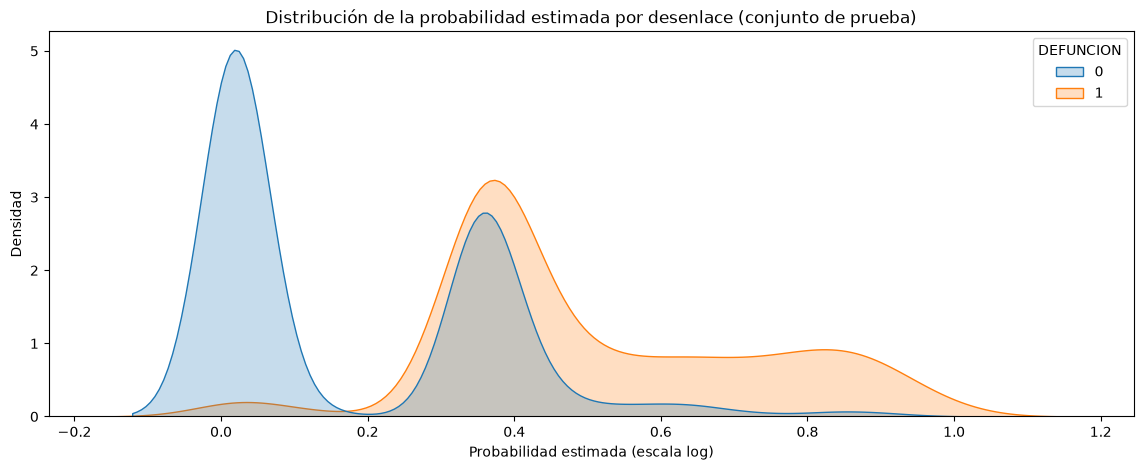

,mean,25%,50%,75%
Sobrevivió (0),0.1760,0.0161,0.0252,0.3538
Falleció (1),0.5081,0.3576,0.4052,0.6701


In [25]:
# Probabilidades estimadas en entrenamiento y prueba
prob_train = modelo_final.predict(sm.add_constant(X_train[variables]))
prob_test = modelo_final.predict(sm.add_constant(X_test[variables]))

def distribution_prob(y_real, probs, titulo):
    datos = pd.DataFrame({'DEFUNCION': y_real.values, 'predicted_probs': probs.values})
    plt.figure(figsize=(14, 5))
    sns.kdeplot(data=datos, x='predicted_probs', hue='DEFUNCION', fill=True, common_norm=False)
    plt.xlabel('Probabilidad estimada (escala log)')
    plt.ylabel('Densidad')
    plt.title(titulo)
    plt.show()

distribution_prob(y_test, prob_test, 'Distribución de la probabilidad estimada por desenlace (conjunto de prueba)')

pd.DataFrame({'Sobrevivió (0)': prob_test[y_test == 0].describe(),
              'Falleció (1)': prob_test[y_test == 1].describe()}).T[['mean', '25%', '50%', '75%']].round(4)

**Interpretación.**

- La distribución de los **sobrevivientes** tiene su pico principal alrededor de 2 % (mediana de 2.5 %), mientras que la de los **fallecidos** se concentra entre 30 % y 70 % (mediana de 40.5 %). La probabilidad promedio de los fallecidos (51 %) es casi 3 veces la de los sobrevivientes (18 %).
- Las distribuciones tienen **dos grupos**: el pico de la izquierda corresponde a pacientes **ambulatorios** y el de la derecha a **hospitalizados**. Casi todos los fallecidos están en el grupo de la derecha.
- La separación **no es perfecta**: los sobrevivientes que fueron hospitalizados (el segundo pico azul, alrededor de 35 %) se traslapan con los fallecidos. Dentro de los hospitalizados el modelo distingue menos, porque solo cuenta con la edad y las comorbilidades para diferenciarlos.
- Estas probabilidades están en la escala de la muestra balanceada. En la población real (0.70 % de mortalidad) serían mucho menores, pero el **orden** de los pacientes, y por lo tanto la separación entre grupos, es el mismo.

## 8. Métricas de desempeño

Definiciones (clase positiva = fallecido):

- **Accuracy**: proporción de predicciones correctas. Es engañosa con clases desbalanceadas.
- **Precision**: de los pacientes que el modelo marca como "fallece", qué proporción realmente falleció.
- **Recall (sensibilidad)**: de los pacientes que realmente fallecieron, qué proporción detectó el modelo.
- **F1-score**: media armónica de precision y recall.

En este problema, un **falso negativo** (no detectar a un paciente que va a morir) es mucho más costoso que un **falso positivo** (vigilar de más a un paciente que sobrevive), por lo que el **recall** de la clase 1 es la métrica más importante.

### 8.1 Umbral de 0.5

In [26]:
umbral = 0.2
for nombre, y_real, prob in [('ENTRENAMIENTO', y_train, prob_train), ('PRUEBA', y_test, prob_test)]:
    y_pred = (prob >= umbral).astype(int)
    print(f'===== {nombre} (umbral = {umbral}) =====')
    print('Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)')
    print(confusion_matrix(y_real, y_pred))
    print(classification_report(y_real, y_pred, digits=3))

===== ENTRENAMIENTO (umbral = 0.2) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[2285 1417]
 [  51 1183]]
              precision    recall  f1-score   support

           0      0.978     0.617     0.757      3702
           1      0.455     0.959     0.617      1234

    accuracy                          0.703      4936
   macro avg      0.717     0.788     0.687      4936
weighted avg      0.847     0.703     0.722      4936

===== PRUEBA (umbral = 0.2) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[941 646]
 [ 19 510]]
              precision    recall  f1-score   support

           0      0.980     0.593     0.739      1587
           1      0.441     0.964     0.605       529

    accuracy                          0.686      2116
   macro avg      0.711     0.779     0.672      2116
weighted avg      0.845     0.686     0.706      2116



**Interpretación (umbral de 0.5).**

- Con el *undersampling*, el umbral de 0.5 **ya no es inútil**: en prueba detecta **213 de 529 fallecidos** (recall de 40 %), mientras que sin *undersampling* detectaba solo 1. Esto ocurre porque ahora los hospitalizados de mayor edad o con comorbilidades sí superan 50 % de probabilidad.
- **Precision de 74 %:** de cada 100 pacientes marcados como "fallece", 74 fallecieron. Este valor es alto porque el conjunto de prueba tiene 25 % de fallecidos; en la población real sería mucho menor (ver sección 8.4).
- **Accuracy de 81.6 %:** solo un poco mayor que el 75 % que se obtendría prediciendo que nadie fallece.
- Aun así, **el recall de 40 % es insuficiente**: el modelo deja pasar al 60 % de los pacientes que fallecen, que es el error más costoso en este problema.
- Las métricas de entrenamiento y prueba son parecidas (recall de 37 % y 40 %), por lo que **no hay sobreajuste**.

**Conclusión:** el umbral de 0.5 sigue sin ser adecuado para el objetivo de detectar a los pacientes en riesgo. Se elige otro umbral con la curva ROC.

### 8.2 Curva ROC y ROC-AUC

La **curva ROC** grafica, para todos los umbrales posibles, la tasa de verdaderos positivos (recall) contra la tasa de falsos positivos (1 − especificidad). El área bajo la curva (**ROC-AUC**) es la probabilidad de que, al tomar al azar un fallecido y un sobreviviente, el modelo le asigne mayor probabilidad al fallecido. Un valor de 0.5 equivale a adivinar al azar y 1 a una clasificación perfecta. Como regla general: 0.7–0.8 es aceptable, 0.8–0.9 es bueno y más de 0.9 es excelente.

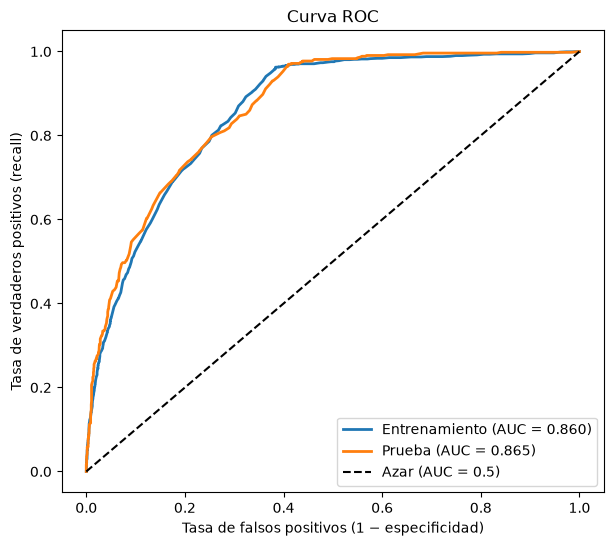

In [17]:
plt.figure(figsize=(7, 6))
for nombre, y_real, prob in [('Entrenamiento', y_train, prob_train), ('Prueba', y_test, prob_test)]:
    fpr, tpr, _ = roc_curve(y_real, prob)
    plt.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc_score(y_real, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0.5)')
plt.xlabel('Tasa de falsos positivos (1 − especificidad)')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curva ROC')
plt.legend()
plt.show()

**Interpretación.**

- El **ROC-AUC es de 0.860 en entrenamiento y 0.865 en prueba**: el modelo tiene una **buena capacidad de discriminación**. Si se elige al azar un paciente que falleció y uno que sobrevivió, en el 86.5 % de los casos el modelo asigna mayor probabilidad al que falleció.
- Es prácticamente el mismo AUC que el modelo sin *undersampling* (0.863). El submuestreo **no mejoró la capacidad del modelo para ordenar el riesgo**; lo que cambia es la escala de las probabilidades y, por lo tanto, el umbral.
- A diferencia de la accuracy y la precision, el AUC **no depende de la proporción de clases**, por lo que es la métrica más adecuada para comparar ambos enfoques.
- Las curvas de entrenamiento y prueba prácticamente se encimadan, lo que confirma que el modelo **generaliza bien** a datos nuevos.
- La curva sube rápido hasta un recall de ~0.96 con una tasa de falsos positivos cercana a 0.4; ese "codo" corresponde a separar pacientes hospitalizados de ambulatorios.

### 8.3 Umbral elegido con la curva ROC

Se elige el umbral que **maximiza la diferencia entre la tasa de verdaderos positivos y la de falsos positivos** (índice de Youden, $TPR - FPR$), que corresponde al punto de la curva ROC más alejado de la diagonal. El umbral se calcula **solo con entrenamiento** y después se aplica a prueba.

In [18]:
fpr, tpr, umbrales = roc_curve(y_train, prob_train)
umbral_roc = umbrales[np.argmax(tpr - fpr)]
print(f'Umbral elegido: {umbral_roc:.4f}  ({umbral_roc * 100:.2f} %)\n')

for nombre, y_real, prob in [('ENTRENAMIENTO', y_train, prob_train), ('PRUEBA', y_test, prob_test)]:
    y_pred = (prob >= umbral_roc).astype(int)
    print(f'===== {nombre} (umbral = {umbral_roc:.4f}) =====')
    print('Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)')
    print(confusion_matrix(y_real, y_pred))
    print(classification_report(y_real, y_pred, digits=3))

Umbral elegido: 0.1434  (14.34 %)

===== ENTRENAMIENTO (umbral = 0.1434) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[2280 1422]
 [  46 1188]]
              precision    recall  f1-score   support

           0      0.980     0.616     0.756      3702
           1      0.455     0.963     0.618      1234

    accuracy                          0.703      4936
   macro avg      0.718     0.789     0.687      4936
weighted avg      0.849     0.703     0.722      4936

===== PRUEBA (umbral = 0.1434) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[938 649]
 [ 17 512]]
              precision    recall  f1-score   support

           0      0.982     0.591     0.738      1587
           1      0.441     0.968     0.606       529

    accuracy                          0.685      2116
   macro avg      0.712     0.779     0.672      2116
weighted avg      0.847     0.685     0.705      2116



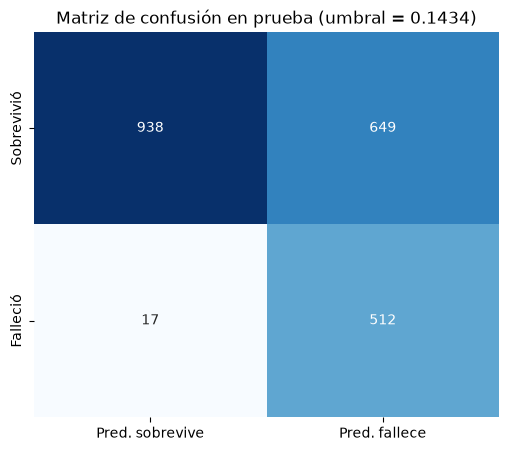

In [19]:
# Matriz de confusión del conjunto de prueba con el umbral elegido
matriz = confusion_matrix(y_test, (prob_test >= umbral_roc).astype(int))
plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['Pred. sobrevive', 'Pred. fallece'], yticklabels=['Sobrevivió', 'Falleció'])
plt.title(f'Matriz de confusión en prueba (umbral = {umbral_roc:.4f})')
plt.show()

**Interpretación (umbral de 14.3 %).**

- El umbral elegido es **0.1434**: un paciente se marca como "alto riesgo" si su probabilidad estimada (en la escala de la muestra) es mayor a 14.3 %. Es bastante menor que 0.5 porque prioriza detectar fallecidos.
- **Recall de 96.8 % en prueba:** el modelo detecta **512 de los 529 fallecidos** y solo deja pasar 17. En entrenamiento el recall es de 96.3 %, así que el resultado es estable.
- **Precision de 44 %:** de cada 100 pacientes marcados como alto riesgo, 44 fallecen. El modelo marca a 1,161 de 2,116 pacientes de prueba (55 %). Esta precision está **inflada por la proporción de 25 % de fallecidos** en el conjunto de prueba.
- **F1 de 0.61 y accuracy de 68.5 %:** también dependen de la proporción de clases, así que no se pueden comparar con las del modelo sin *undersampling*.
- La pregunta práctica es cómo se comporta el modelo con la proporción real de fallecidos, que se revisa a continuación.

### 8.4 Desempeño con la proporción real de fallecidos

Las métricas anteriores se calcularon en un conjunto de prueba con 25 % de fallecidos. En la población real solo fallece el 0.70 %, y la **precision** depende mucho de esa proporción: con menos fallecidos, una mayor parte de los pacientes marcados como alto riesgo son sobrevivientes.

Para medirlo se arma un conjunto de prueba con la proporción real usando **solo pacientes que el modelo nunca vio**: los 529 fallecidos del conjunto de prueba y una muestra aleatoria de los sobrevivientes que quedaron **fuera** del *undersampling*, en la cantidad necesaria para que la mortalidad sea de 0.70 %. Se usa el mismo umbral de la sección 8.3; como corregir el intercepto no cambia el orden de los pacientes, el umbral equivale a lo mismo en la escala real.

In [20]:
pi_real = dengue['DEFUNCION'].mean()
fallecidos_prueba = dengue.loc[y_test.index[y_test == 1]]
sobrevivientes_fuera = dengue.drop(index=dengue_us.index)          # sobrevivientes no usados en el undersampling
n_sobrevivientes = round(len(fallecidos_prueba) * (1 - pi_real) / pi_real)
prueba_real = pd.concat([fallecidos_prueba, sobrevivientes_fuera.sample(n_sobrevivientes, random_state=42)])

prob_real = modelo_final.predict(sm.add_constant(prueba_real[variables]))
y_pred_real = (prob_real >= umbral_roc).astype(int)
print(f'Pacientes: {len(prueba_real):,} | fallecidos: {prueba_real["DEFUNCION"].sum()} '
      f'| mortalidad: {prueba_real["DEFUNCION"].mean() * 100:.2f} %')
print(f'ROC-AUC: {roc_auc_score(prueba_real["DEFUNCION"], prob_real):.3f}')
print(f'Pacientes marcados como alto riesgo: {y_pred_real.mean() * 100:.1f} %')
print(f'Valor predictivo negativo (sobreviven entre los de bajo riesgo): '
      f'{1 - prueba_real.loc[y_pred_real == 0, "DEFUNCION"].mean():.4%}\n')
print('Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)')
print(confusion_matrix(prueba_real['DEFUNCION'], y_pred_real))
print(classification_report(prueba_real['DEFUNCION'], y_pred_real, digits=3))

Pacientes: 75,584 | fallecidos: 529 | mortalidad: 0.70 %
ROC-AUC: 0.865
Pacientes marcados como alto riesgo: 39.2 %
Valor predictivo negativo (sobreviven entre los de bajo riesgo): 99.9630%

Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[45905 29150]
 [   17   512]]
              precision    recall  f1-score   support

           0      1.000     0.612     0.759     75055
           1      0.017     0.968     0.034       529

    accuracy                          0.614     75584
   macro avg      0.508     0.790     0.396     75584
weighted avg      0.993     0.614     0.754     75584



**Interpretación (proporción real de 0.70 %).**

- **El recall no cambia (96.8 %)** ni el ROC-AUC (0.865), porque no dependen de cuántos sobrevivientes haya.
- **La precision cae de 44 % a 1.7 %:** con la proporción real, por cada fallecido hay 142 sobrevivientes, y el modelo marca como alto riesgo al **39 %** de ellos (29,150 pacientes) para capturar a 512 fallecidos. Con un evento tan raro, una precision baja es inevitable con cualquier umbral de recall alto.
- **Valor práctico:** un paciente clasificado como "bajo riesgo" sobrevive en el **99.96 %** de los casos (45,905 de 45,922). El modelo es muy útil para **descartar** riesgo y concentrar la vigilancia en el 39 % de los pacientes donde ocurren el 97 % de las muertes.
- **Comparación con el modelo sin *undersampling*:** los resultados son prácticamente iguales (antes: recall 96.6 %, precision 1.7 %, 39 % de pacientes marcados). El *undersampling* lleva a un modelo con la **misma capacidad predictiva** usando el 3 % de los datos, pero con menos variables significativas.

## 9. Conclusiones

### ¿El modelo captura el comportamiento de la variable de respuesta?

Sí, de forma **buena para discriminar** y **limitada para confirmar**:

- Con un **ROC-AUC de 0.865** en prueba, el modelo ordena correctamente el riesgo en el 86.5 % de los pares fallecido–sobreviviente, y el desempeño es igual en entrenamiento y prueba (no hay sobreajuste).
- Con el umbral elegido por la curva ROC (14.3 % en la escala de la muestra), detecta al **96.8 % de los fallecidos** del conjunto de prueba. Con la proporción real de mortalidad, solo el 1.7 % de los pacientes marcados como alto riesgo fallece, pero el 99.96 % de los marcados como bajo riesgo sobrevive. El modelo sirve para **descartar riesgo**, no para predecir con certeza quién morirá.
- El umbral de 0.5 detecta solo al 40 % de los fallecidos; no es adecuado para este problema.

### Efecto del *undersampling*

- **No mejoró la capacidad predictiva:** el ROC-AUC (0.865 vs. 0.863), el recall y la precision con la proporción real son prácticamente iguales a los del modelo con todos los datos.
- **Los *odds ratios* de las variables principales se mantienen** (hospitalización ≈ 34, enfermedad renal ≈ 3.4, diabetes ≈ 2), porque el muestreo solo depende del desenlace.
- **Las probabilidades quedan infladas** (escala de 25 % de mortalidad) y hay que corregir el intercepto para interpretarlas en la población real.
- **Se pierde potencia estadística:** al usar solo el 2 % de los sobrevivientes, cirrosis, inmunosupresión y los meses de abril y junio dejan de ser significativos, y aparece DENV4 con un efecto basado en apenas 31 pacientes de entrenamiento.

### Importancia de las variables y hallazgos del EDA

1. **Hospitalización:** la variable más importante (OR = 34). El 96 % de los fallecidos estuvo hospitalizado. Refleja la gravedad del paciente; sin ella, el AUC cae a 0.70.
2. **Edad:** la mortalidad tiene forma de "U" en el log-odds (mínima alrededor de los 23–24 años, alta en menores de 5 y muy alta en adultos mayores), por lo que fue necesario incluir **edad²** (el AIC baja 57 unidades). Los mayores de 60 años son el 6.6 % de los pacientes pero el 25 % de las muertes.
3. **Comorbilidades:** enfermedad renal (OR = 3.4), manifestaciones hemorrágicas (3.1) y diabetes (2.0) aumentan significativamente el riesgo. Cirrosis e inmunosupresión eran significativas con todos los datos, pero no con la muestra reducida.
4. **DENV4:** OR = 5.0 con un intervalo muy amplio (1.6–15.7); su mortalidad en los datos completos (0.86 %) es casi igual a la general. Se considera un resultado poco confiable.
5. **Variables sin efecto:** sexo, embarazo, entidad costera, hipertensión, los demás serotipos y los meses no son significativos al ajustar por las demás variables. La hipertensión era importante en el EDA, pero su efecto se explica por la edad y la diabetes, con las que está correlacionada.

### Recomendaciones y mejoras futuras

- **Uso del modelo:** como herramienta de **tamizaje**, para priorizar la vigilancia de pacientes hospitalizados, mayores de 60 años, menores de 5 años o con enfermedad renal, diabetes o manifestaciones hemorrágicas.
- **Estabilidad del *undersampling*:** repetir el submuestreo con distintas semillas (`random_state`) para ver qué variables se seleccionan de forma consistente; es probable que DENV4 no aparezca en todas las repeticiones.
- **Otras formas de manejar el desbalance:** comparar con pesos por clase (`class_weight`) o sobremuestreo, que no descartan información.
- **Agregar variables clínicas:** los datos no incluyen signos de alarma, resultados de laboratorio (plaquetas, hematocrito) ni días desde el inicio de síntomas, que probablemente explican buena parte de la mortalidad no capturada.
- **Separar el análisis por tipo de paciente:** un modelo solo con pacientes hospitalizados permitiría distinguir mejor el riesgo dentro del grupo donde ocurren casi todas las muertes.
- **Calidad de los datos:** son datos de vigilancia epidemiológica y puede haber subregistro de comorbilidades; además, una asociación en el modelo no implica causalidad.

### Insights principales

- **1 de cada 142** pacientes con dengue confirmado fallece, pero el riesgo está muy concentrado: el 39 % de los pacientes (marcados como alto riesgo) concentra el 97 % de las muertes.
- Un paciente **hospitalizado de 85 años** sin comorbilidades tiene una probabilidad estimada de fallecer de **12.3 %**, contra **1.1 %** a los 20 años.
- La **enfermedad renal** es la comorbilidad más peligrosa: 12.2 % de mortalidad en quienes la tienen, 18 veces la de quienes no (0.67 %).
- Balancear las clases **no hace mejor al modelo**: cambia la escala de las probabilidades y el umbral, pero la capacidad de distinguir a los pacientes en riesgo es la misma.